In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

Hypotese 2: Pokemon av typen normal er i større grad basert på ekte dyr. De bør derfor følge kvadrat-kube-loven bedre enn andre typer. 
Kan avviket fra loven kvadrat-kube-loven forutsi om et evolusjonssteg er av typen normal?

Respons er 1 hvis den er normal og 0 dersom den ikke er det.
Forklaringsvariabel er absoluttverdien av avviket.
Vi bruker logistisk regresjon som evalueres med sensitivitet og spesifisitet på et testsett.


In [82]:
pokedex = pd.read_csv("pokemon.csv")

forrige = pokedex[["id", "name", "height_m", "weight_kg"]]
pairs = pokedex.merge(forrige, left_on="evolves_from_id", right_on="id", suffixes=("", "_prev"))

pairs["log_h_ratio"] = np.log(pairs["height_m"] / pairs["height_m_prev"])
pairs["log_w_ratio"] = np.log(pairs["weight_kg"] / pairs["weight_kg_prev"])
pairs["normal"] = ((pairs["type1"] == "normal") | (pairs["type2"] == "normal")).astype(int)

# Avvik fra kvadrat-kube-loven (0 = følger loven perfekt)
pairs["avvik"] = pairs["log_w_ratio"] - 3 * pairs["log_h_ratio"]
pairs["abs_avvik"] = pairs["avvik"].abs()

print(pairs["normal"].value_counts())

normal
0    426
1     58
Name: count, dtype: int64


Datasettet har 426 + 58 = 484 evolusjonssteg. Bare 58 av de er normal type, så en modell som alltid gjetter "ikke normal" vil derfor få mye riktig selv om den ikke har lært noe.

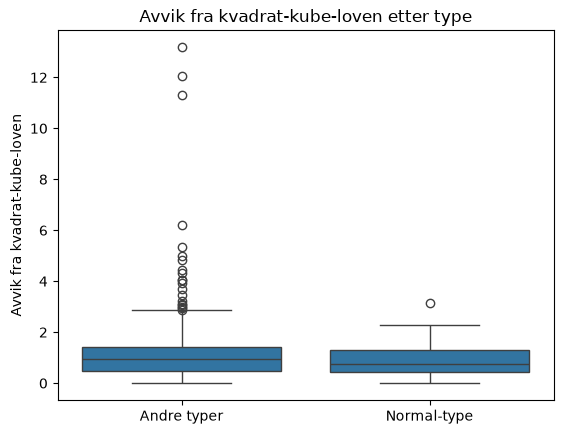

In [83]:
sns.boxplot(x="normal", y="abs_avvik", data=pairs)
plt.xticks([0, 1], ["Andre typer", "Normal-type"])
plt.xlabel("")
plt.ylabel("Avvik fra kvadrat-kube-loven")
plt.title("Avvik fra kvadrat-kube-loven etter type")
plt.show()

Vi kan se på boksplottet at normal typene har litt lavere median avvik, og mye mindre spredning enn andre typer. 

In [84]:
# 70 % trening, 30 % test. stratify sørger for lik andel Normal-type i begge settene
tren, test = train_test_split(pairs, test_size=0.3, random_state=1, stratify=pairs["normal"])

print("Trening:", len(tren), ", Normal:", tren["normal"].sum())
print("Test:", len(test), ", Normal:", test["normal"].sum())

Trening: 338 , Normal: 41
Test: 146 , Normal: 17


Vi deler dataene i et treningssett som er 70% og et test sett som er 30%. Så modellen trenes på treningssettet og evalueres på test settet. 

In [85]:
logit_modell = smf.logit("normal ~ abs_avvik", data=tren).fit()
print(logit_modell.summary())

Optimization terminated successfully.
         Current function value: 0.365188
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 normal   No. Observations:                  338
Model:                          Logit   Df Residuals:                      336
Method:                           MLE   Df Model:                            1
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                 0.01170
Time:                        12:13:06   Log-Likelihood:                -123.43
converged:                       True   LL-Null:                       -124.89
Covariance Type:            nonrobust   LLR p-value:                   0.08737
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.6447      0.267     -6.164      0.000      -2.168      -1.122
abs_avvik     -0.3336      0.

Koeffisienten for avviket er negativt. Dette stemmer med hypotesen ettersom at jo mindre avvik, jo høyere sannsynlighet for normal type. 

In [86]:
test_prob = logit_modell.predict(test)
print(test_prob.describe())

count    146.000000
mean       0.122593
std        0.026589
min        0.037185
25%        0.107278
50%        0.124775
75%        0.141951
max        0.161828
dtype: float64


Modellen gir hvert evolusjonssteg i testsettet en sannsynlighet for å være normal type. 
Alle sannsynlighetene ligger mellom 0.04 og 0.16, hvor gjennomsnittet er 0.12.
Standardavviket er bare 0.027.

Siden standardavviket fra er såpass lite, gir den nesten alle steg samme sannsynlighet som ligger langt under cutoff på 0.5.
Da vil den klassifisere alle pokemon som annen type, slik vi ser i forvirringsmatrisen under.

In [87]:
test_pred = (test_prob > 0.5).astype(int)

pd.DataFrame(
    confusion_matrix(y_true=test["normal"], y_pred=test_pred, labels=[0, 1]),
    index=["sann: annen", "sann: Normal"],
    columns=["pred: annen", "pred: Normal"]
)

,pred: annen,pred: Normal
sann: annen,129,0
sann: Normal,17,0


In [88]:
# Cutoff = andelen Normal-type i treningssettet (valgt uten å se på testsettet)
cutoff = tren["normal"].mean()
print("Cutoff:", round(cutoff, 3))

# Sjekk: gjennomsnittlig predikert sannsynlighet på treningssettet er lik andelen Normal
print("Gj.snitt predikert sannsynlighet (trening):", round(logit_modell.predict(tren).mean(), 3))

# Klassifiser testsettet med den nye cutoff-verdien
test_pred = (test_prob > cutoff).astype(int)

# Sensitivitet, spesifisitet og nøyaktighet
tn, fp, fn, tp = confusion_matrix(test["normal"], test_pred, labels=[0, 1]).ravel()
print("Sensitivitet:", round(tp / (tp + fn), 2))
print("Spesifisitet:", round(tn / (tn + fp), 2))
print("Nøyaktighet:", round((tp + tn) / len(test), 2))

# Forvirringsmatrise
pd.DataFrame(
    confusion_matrix(y_true=test["normal"], y_pred=test_pred, labels=[0, 1]),
    index=["sann: annen", "sann: Normal"],
    columns=["pred: annen", "pred: Normal"]
)

Cutoff: 0.121
Gj.snitt predikert sannsynlighet (trening): 0.121
Sensitivitet: 0.65
Spesifisitet: 0.43
Nøyaktighet: 0.46


,pred: annen,pred: Normal
sann: annen,56,73
sann: Normal,6,11


Siden bare 12% av evolusjonsstegene er av typen normal, gir cutoff 0,5 ingen normal prediksjoner.
Vi bruker derfor andelen normal i treningssettet (0,121) som cutoff. Da gjetter modellen
normal når avviket gjør steget mer sannsynlig enn gjennomsnittet å være normal type.

Modellen finner nå 11 av 17 normal typer (sensitivitet 0,65), men klassifiserer også 73 av
129 andre typer feil som normal (spesifisitet 0,43). Avviket skiller altså nesten ikke normal typer
fra andre typer.

In [89]:
resultater = []
for cutoff in np.arange(0.05, 0.25, 0.025):
    pred = (test_prob > cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(test["normal"], pred, labels=[0, 1]).ravel()
    resultater.append({
        "cutoff": round(cutoff, 3),
        "sensitivitet": tp / (tp + fn), # andel Normal som blir funnet
        "spesifisitet": tn / (tn + fp), # andel andre typer som blir riktig klassifisert
        "nøyaktighet": (tp + tn) / len(test),
    })

resultater = pd.DataFrame(resultater)
print(resultater.round(2))

   cutoff  sensitivitet  spesifisitet  nøyaktighet
0    0.05          1.00          0.03         0.14
1    0.08          0.94          0.05         0.15
2    0.10          0.94          0.20         0.29
3    0.12          0.65          0.52         0.53
4    0.15          0.12          0.82         0.74
5    0.18          0.00          1.00         0.88
6    0.20          0.00          1.00         0.88
7    0.22          0.00          1.00         0.88


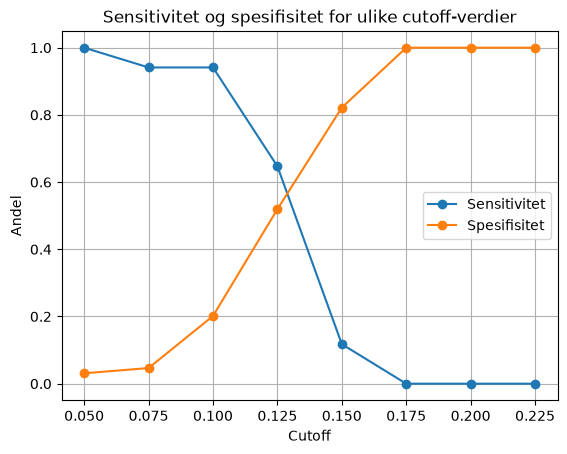

In [90]:
plt.plot(resultater["cutoff"], resultater["sensitivitet"], marker="o", label="Sensitivitet")
plt.plot(resultater["cutoff"], resultater["spesifisitet"], marker="o", label="Spesifisitet")
plt.xlabel("Cutoff")
plt.ylabel("Andel")
plt.title("Sensitivitet og spesifisitet for ulike cutoff-verdier")
plt.legend()
plt.grid()
plt.show()

Tabellen og plottet viser en avveining. Når cutoff senkes, finner modellen flere
normal (sensitiviteten øker), men klassifiserer også flere andre typer feil som normal
(spesifisiteten synker). Nøyaktigheten er høyest (0,88) når modellen ikke predikerer noen
normal typer i det hele tatt. Det viser at nøyaktighet er et misvisende mål når klassene er
så ubalanserte.